In [18]:
# import paulssonlab.deaton.trenchripper.trenchripper as tr
# import trenchripper as tr
import trenchripper as tr

import warnings

warnings.filterwarnings(action="once")

import matplotlib

matplotlib.rcParams["figure.figsize"] = [20, 10]

import glob
import os
import shutil
import re
import pandas as pd
import h5py
import numpy as np
import skimage as sk
import matplotlib.pyplot as plt

import utils

# addition of active memory manager
import dask
dask.config.set({'distributed.scheduler.active-memory-manager.start': True});
dask.config.set({'distributed.scheduler.worker-ttl': "5m"});
dask.config.set({'distributed.scheduler.allowed-failures': 100});

dask_wd = "/home/lag36/scratch/lag36/dask"

In [ ]:
def merge_channels_into_projection_image(filename,
                                         channels_to_merge = ['RFP', 'Cy5', 'Cy7'],
                                         ):
    image_projection_all_channels = {}
    with h5py.File(filename, 'r') as f:
        for channel in channels_to_merge:
            n_timepoints = f[channel].shape[0]
            images_all_timepoints = f[channel][:]
            image_projection_all_channels[channel] = np.percentile(images_all_timepoints, 98, axis=0) / np.max(images_all_timepoints)

    image_projection_combined = \
        sk.util.img_as_uint(
            np.percentile(
                np.stack(
                    [image_projection_all_channels[channel] for channel in channels_to_merge],
                    axis=0
                )  
                ,98, axis=0
            )
        )

    img_projection_combined_all_timepoints = np.stack(
        [image_projection_combined for _ in range(n_timepoints)],
        axis=0
    )
    
    return img_projection_combined_all_timepoints

def save_image_projection_as_new_channel(img_projection_combined_all_timepoints, filename, channel_name_out='SEG'):
    with h5py.File(filename, 'r+') as f:
        if channel_name_out in f.keys():
            del f[channel_name_out]
        f.create_dataset(channel_name_out, data=img_projection_combined_all_timepoints, dtype='uint16')
    return 0

def generate_and_save_image_projection_as_new_channel(
    fov:int,
    filenames_all_fovs:dict,
    channels_to_merge=['RFP', 'Cy5', 'Cy7'],
    channel_name_out='SEG'
):
    filename = filenames_all_fovs[fov]
    img_projection_combined_all_timepoints = merge_channels_into_projection_image(
        filename,
        channels_to_merge=channels_to_merge,
    )
    save_image_projection_as_new_channel(
        img_projection_combined_all_timepoints,
        filename,
        channel_name_out=channel_name_out
    )
    return 0

In [43]:
channels_to_merge = ['RFP', 'Cy5', 'Cy7']
CHANNEL_NAME_OUT = 'SEG'

headpath = '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/Barcodes/'
headpath_hdf5 = headpath+'/hdf5/'
full_filepaths_hdf5 = glob.glob(headpath_hdf5 + '/*.hdf5')
# filenames_hdf5 = [filename.split('/')[-1] for filename in full_filepaths_hdf5]

filenames_all_fovs = {
    int(re.search(r'hdf5_(\d+)\.hdf5', filename).group(1)): filename
    for filename in full_filepaths_hdf5
}

# Sort the dictionary by keys
filenames_all_fovs = dict(sorted(filenames_all_fovs.items()))

In [ ]:
generate_and_save_image_projection_as_new_channel(
    fov=0,
    filenames_all_fovs=filenames_all_fovs,
    channels_to_merge=channels_to_merge,
    channel_name_out=CHANNEL_NAME_OUT
)

0

In [27]:
dask_wd = "/home/lag36/scratch/lag36/dask"
dask_controller = tr.trcluster.dask_controller(
    walltime="0:30:00",
    local=False,
    n_workers=200,
    n_workers_min=20,
    memory="2GB",
    working_directory=dask_wd,
)
dask_controller.startdask()
dask_controller.displaydashboard()

20m
0:30:00


In [28]:
fovs = list(filenames_all_fovs.keys())

In [31]:
df_futures = utils.deploy_function_in_dask(dask_controller=dask_controller,
                                           headpath=headpath,
                                           function=generate_and_save_image_projection_as_new_channel,
                                           indices = fovs,
                                           filenames_all_fovs=filenames_all_fovs,
                                           channels_to_merge=['RFP', 'Cy5', 'Cy7'],
                                           channel_name_out='SEG')

In [38]:
dask_controller.shutdown()

Done.


2025-07-31 12:22:05,611 - distributed.deploy.adaptive_core - INFO - Adaptive stop


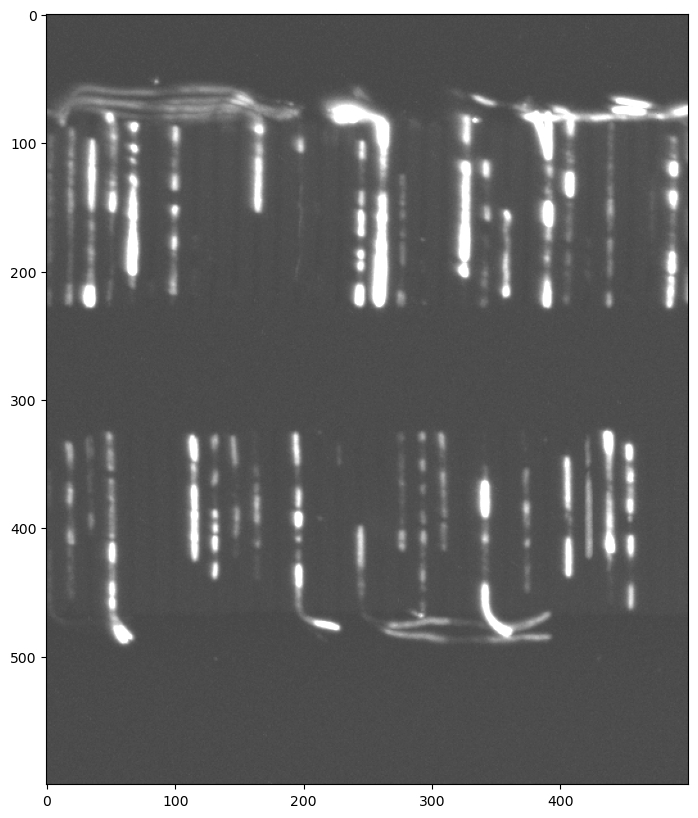

In [37]:
with h5py.File(filenames_all_fovs[0], 'r') as f:
    plt.imshow(f['SEG'][0][600:1200,1000:1500], cmap='gray', vmin = 500, vmax=15000)

### Change metadata.hdf5

In [41]:
metadata = pd.read_hdf(headpath + 'metadata.hdf5')

In [47]:
metadata.head(1)

,,channel_paths,config,t,x,y,z,File Index,Image Index
fov,timepoints,,,,,,,,
0,0,{'BF': '/home/lag36/scratch/lag36/2025-07-13_l...,BF,0.557,7396.0,14167.9,2814.26,0,0


In [50]:
metadata['channel_paths'][0,0]

{'BF': '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run_drift_corrected/fov=0_config=BF_t=1.hdf5',
 'Cy5': '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run_drift_corrected/fov=0_config=Cy5_t=1.hdf5',
 'Cy7': '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run_drift_corrected/fov=0_config=Cy7_t=1.hdf5',
 'RFP': '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run_drift_corrected/fov=0_config=RFP_t=1.hdf5'}

In [65]:
headpath

'/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/Barcodes/'

In [ ]:
CHANNEL_REFERENCE = 'RFP'

def update_channel_paths(row):
    channel_paths = row['channel_paths']
    new_key = CHANNEL_NAME_OUT
    new_value = channel_paths[CHANNEL_REFERENCE].replace(CHANNEL_REFERENCE, new_key)
    return channel_paths | {new_key: new_value}

metadata['channel_paths'] = metadata.apply(update_channel_paths, axis=1)

pd.to_hdf(headpath + 'metadata.hdf5')

In [67]:
pd.to_hdf5(headpath + 'metadata.hdf5')

AttributeError: module 'pandas' has no attribute 'to_hdf5'